Machine learning


In [ ]:
print("Hai ML")

Hai ML


In [ ]:
from sklearn.datasets import load_iris
from sklearn.preprocessing import LabelEncoder,OneHotEncoder, MinMaxScaler, StandardScaler
from sklearn.model_selection import train_test_split
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
iris_data= load_iris()
iris_data

{'data': array([[5.1, 3.5, 1.4, 0.2],
        [4.9, 3. , 1.4, 0.2],
        [4.7, 3.2, 1.3, 0.2],
        [4.6, 3.1, 1.5, 0.2],
        [5. , 3.6, 1.4, 0.2],
        [5.4, 3.9, 1.7, 0.4],
        [4.6, 3.4, 1.4, 0.3],
        [5. , 3.4, 1.5, 0.2],
        [4.4, 2.9, 1.4, 0.2],
        [4.9, 3.1, 1.5, 0.1],
        [5.4, 3.7, 1.5, 0.2],
        [4.8, 3.4, 1.6, 0.2],
        [4.8, 3. , 1.4, 0.1],
        [4.3, 3. , 1.1, 0.1],
        [5.8, 4. , 1.2, 0.2],
        [5.7, 4.4, 1.5, 0.4],
        [5.4, 3.9, 1.3, 0.4],
        [5.1, 3.5, 1.4, 0.3],
        [5.7, 3.8, 1.7, 0.3],
        [5.1, 3.8, 1.5, 0.3],
        [5.4, 3.4, 1.7, 0.2],
        [5.1, 3.7, 1.5, 0.4],
        [4.6, 3.6, 1. , 0.2],
        [5.1, 3.3, 1.7, 0.5],
        [4.8, 3.4, 1.9, 0.2],
        [5. , 3. , 1.6, 0.2],
        [5. , 3.4, 1.6, 0.4],
        [5.2, 3.5, 1.5, 0.2],
        [5.2, 3.4, 1.4, 0.2],
        [4.7, 3.2, 1.6, 0.2],
        [4.8, 3.1, 1.6, 0.2],
        [5.4, 3.4, 1.5, 0.4],
        [5.2, 4.1, 1.5, 0.1],
  

In [ ]:
data=pd.DataFrame(iris_data.data,columns=iris_data.feature_names)
data["target"]= iris_data.target
data

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,2
146,6.3,2.5,5.0,1.9,2
147,6.5,3.0,5.2,2.0,2
148,6.2,3.4,5.4,2.3,2


In [ ]:
data.shape

(150, 5)

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   target             150 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 6.0 KB


In [ ]:
data.isna().sum()

,0
sepal length (cm),0
sepal width (cm),0
petal length (cm),0
petal width (cm),0
target,0


In [ ]:
data.duplicated().sum()

np.int64(1)

In [ ]:
data.groupby('target').size()

,0
target,
0,50
1,50
2,50


In [ ]:
data.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


<Axes: xlabel='target', ylabel='count'>

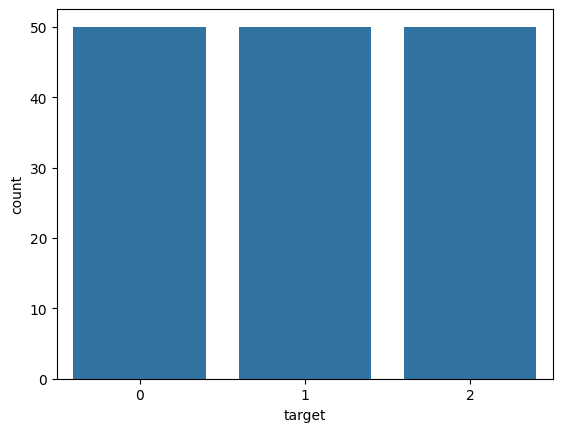

In [ ]:
sns.countplot(x="target",data=data)

<Axes: xlabel='target', ylabel='sepal length (cm)'>

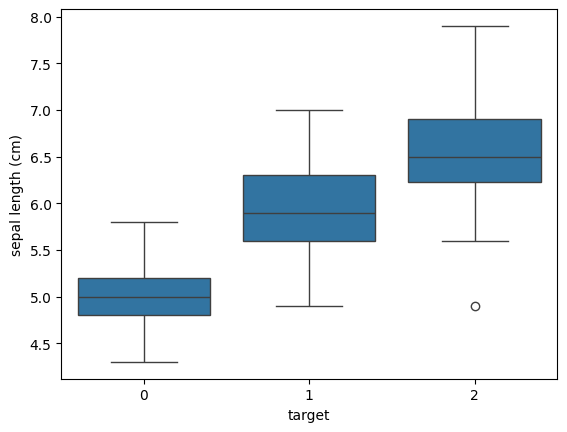

In [ ]:
sns.boxplot(x="target",y="sepal length (cm)",data=data)

<Axes: >

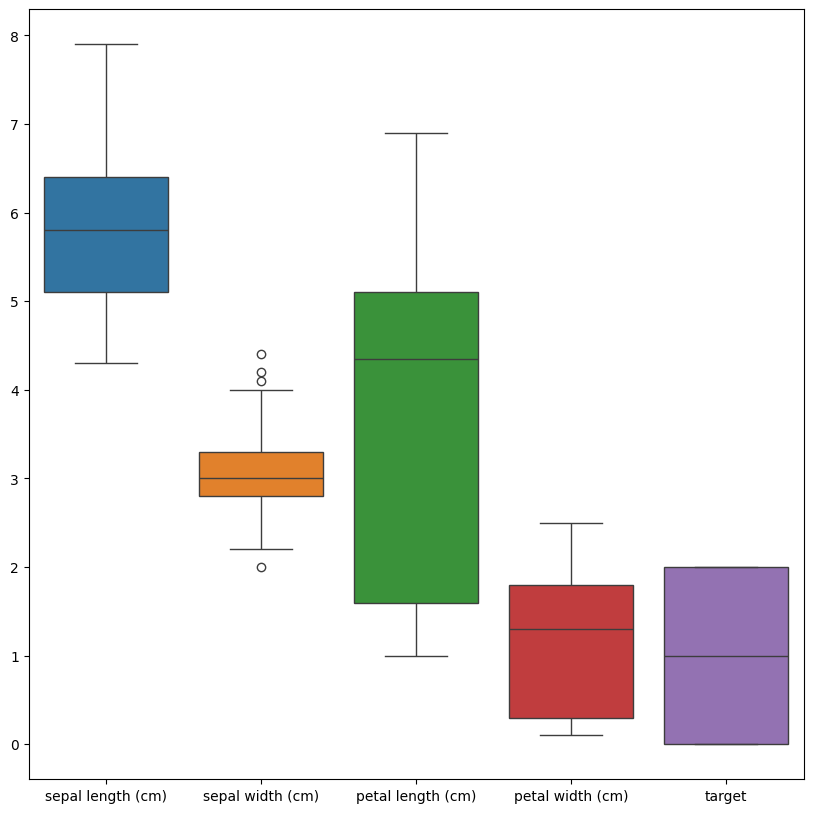

In [ ]:
plt.figure(figsize=(10,10))
sns.boxplot(data=data)

<Axes: xlabel='sepal length (cm)', ylabel='sepal width (cm)'>

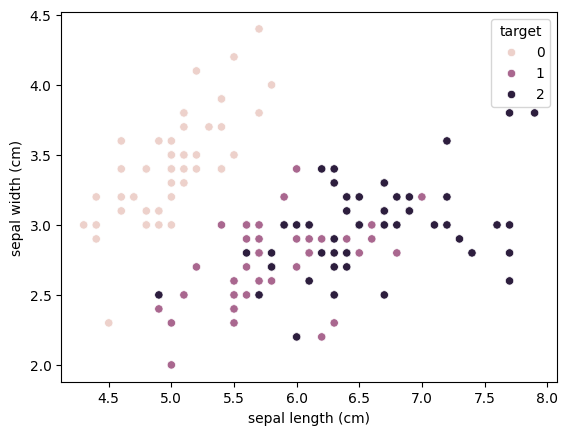

In [ ]:
sns.scatterplot(x="sepal length (cm)",y="sepal width (cm)",hue="target",data=data)

In [ ]:
q1= data["sepal width (cm)"].quantile(0.25)
q2= data["sepal width (cm)"].quantile(0.50)
iqr= q2-q1
lower= q1-1.5*iqr
upper= q2+1.5*iqr
print(lower)
print(upper)

2.4999999999999996
3.3000000000000003


In [ ]:
df=data[(data["sepal width (cm)"]<=upper) & (data["sepal width (cm)"]>=lower)]
df

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
8,4.4,2.9,1.4,0.2,0
9,4.9,3.1,1.5,0.1,0
...,...,...,...,...,...
144,6.7,3.3,5.7,2.5,2
145,6.7,3.0,5.2,2.3,2
146,6.3,2.5,5.0,1.9,2
147,6.5,3.0,5.2,2.0,2


<Axes: >

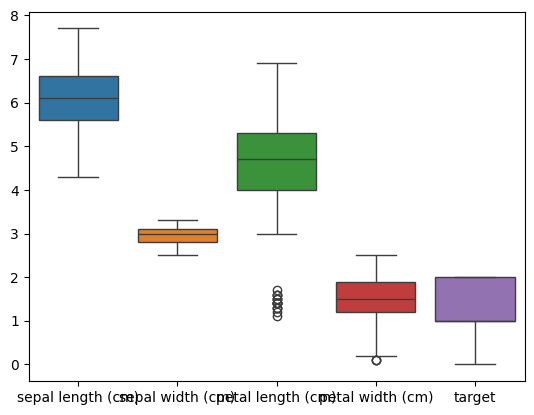

In [ ]:
sns.boxplot(data=df)

In [ ]:
data.drop_duplicates(inplace =True)

In [ ]:
data.duplicated().sum()

np.int64(0)

In [ ]:
#for outliers median
data.fillna(data["sepal width (cm)"].median())

#for outliers mean
data.fillna(data["sepal length (cm)"].mean())

#for categorical data mode
data.fillna(data["target"].mode())

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,2
146,6.3,2.5,5.0,1.9,2
147,6.5,3.0,5.2,2.0,2
148,6.2,3.4,5.4,2.3,2


In [ ]:
#correlation
df.corr(method= 'spearman')

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
sepal length (cm),1.000000,0.072452,0.845137,0.743485,0.697944
sepal width (cm),0.072452,1.000000,-0.041882,0.014405,-0.186917
petal length (cm),0.845137,-0.041882,1.000000,0.908498,0.903274
petal width (cm),0.743485,0.014405,0.908498,1.000000,0.909443
target,0.697944,-0.186917,0.903274,0.909443,1.000000


<Axes: >

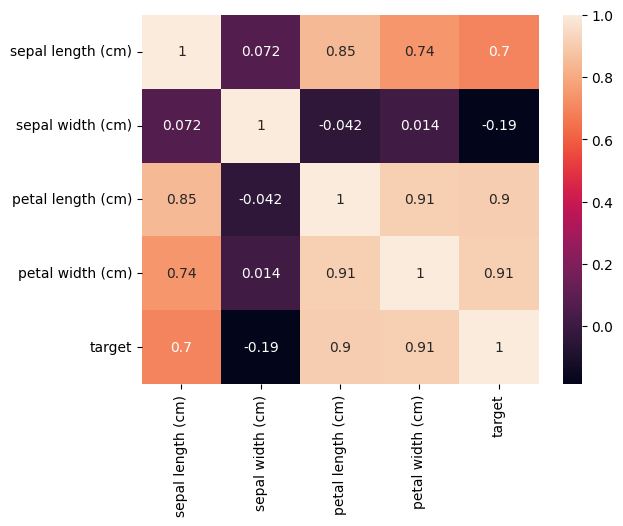

In [ ]:
sns.heatmap(df.corr(method= 'spearman'),annot=True)

In [ ]:
#target- sepal length (cm), petal length (cm), petal width (cm)

In [ ]:
#encoding
le=LabelEncoder()
df["target"]=le.fit_transform(df["target"])
df

/tmp/ipython-input-24254/248125190.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["target"]=le.fit_transform(df["target"])


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
8,4.4,2.9,1.4,0.2,0
9,4.9,3.1,1.5,0.1,0
...,...,...,...,...,...
144,6.7,3.3,5.7,2.5,2
145,6.7,3.0,5.2,2.3,2
146,6.3,2.5,5.0,1.9,2
147,6.5,3.0,5.2,2.0,2


In [ ]:
le.inverse_transform(df["target"])

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2])

In [ ]:
encode=OneHotEncoder()
en=encode.fit_transform(df[["target"]]).toarray()
en

array([[1., 0., 0.],
       [1., 0., 0.],
       [1., 0., 0.],
       [1., 0., 0.],
       [1., 0., 0.],
       [1., 0., 0.],
       [1., 0., 0.],
       [1., 0., 0.],
       [1., 0., 0.],
       [1., 0., 0.],
       [1., 0., 0.],
       [1., 0., 0.],
       [1., 0., 0.],
       [1., 0., 0.],
       [1., 0., 0.],
       [1., 0., 0.],
       [1., 0., 0.],
       [1., 0., 0.],
       [0., 1., 0.],
       [0., 1., 0.],
       [0., 1., 0.],
       [0., 1., 0.],
       [0., 1., 0.],
       [0., 1., 0.],
       [0., 1., 0.],
       [0., 1., 0.],
       [0., 1., 0.],
       [0., 1., 0.],
       [0., 1., 0.],
       [0., 1., 0.],
       [0., 1., 0.],
       [0., 1., 0.],
       [0., 1., 0.],
       [0., 1., 0.],
       [0., 1., 0.],
       [0., 1., 0.],
       [0., 1., 0.],
       [0., 1., 0.],
       [0., 1., 0.],
       [0., 1., 0.],
       [0., 1., 0.],
       [0., 1., 0.],
       [0., 1., 0.],
       [0., 1., 0.],
       [0., 1., 0.],
       [0., 1., 0.],
       [0., 1., 0.],
       [0., 1

In [ ]:
print(en[0])
print(en[34])
print(en[99])

[1. 0. 0.]
[0. 1. 0.]
[0. 0. 1.]


In [ ]:
scaler1=MinMaxScaler()
scaled_data=scaler1.fit_transform(df[["sepal length (cm)"]])

In [ ]:
df["sepal length (cm)"]

,sepal length (cm)
1,4.9
2,4.7
3,4.6
8,4.4
9,4.9
...,...
144,6.7
145,6.7
146,6.3
147,6.5


In [ ]:
scaled_data

array([[0.17647059],
       [0.11764706],
       [0.08823529],
       [0.02941176],
       [0.17647059],
       [0.14705882],
       [0.        ],
       [0.23529412],
       [0.20588235],
       [0.11764706],
       [0.14705882],
       [0.17647059],
       [0.20588235],
       [0.02941176],
       [0.02941176],
       [0.14705882],
       [0.08823529],
       [0.20588235],
       [0.79411765],
       [0.61764706],
       [0.76470588],
       [0.64705882],
       [0.41176471],
       [0.58823529],
       [0.67647059],
       [0.26470588],
       [0.47058824],
       [0.52941176],
       [0.38235294],
       [0.70588235],
       [0.38235294],
       [0.44117647],
       [0.38235294],
       [0.47058824],
       [0.52941176],
       [0.58823529],
       [0.52941176],
       [0.61764706],
       [0.67647059],
       [0.73529412],
       [0.70588235],
       [0.5       ],
       [0.41176471],
       [0.44117647],
       [0.5       ],
       [0.32352941],
       [0.70588235],
       [0.382

In [ ]:
scaler2= StandardScaler()
scaled_data2=scaler2.fit_transform(df[["sepal length (cm)"]])

In [ ]:
scaled_data2

array([[-1.37708449],
       [-1.62243404],
       [-1.74510881],
       [-1.99045837],
       [-1.37708449],
       [-1.49975926],
       [-2.11313314],
       [-1.13173494],
       [-1.25440971],
       [-1.62243404],
       [-1.49975926],
       [-1.37708449],
       [-1.25440971],
       [-1.99045837],
       [-1.99045837],
       [-1.49975926],
       [-1.74510881],
       [-1.25440971],
       [ 1.19908579],
       [ 0.46303714],
       [ 1.07641102],
       [ 0.58571192],
       [-0.39568629],
       [ 0.34036237],
       [ 0.70838669],
       [-1.00906016],
       [-0.15033673],
       [ 0.09501282],
       [-0.51836106],
       [ 0.83106147],
       [-0.51836106],
       [-0.27301151],
       [-0.51836106],
       [-0.15033673],
       [ 0.09501282],
       [ 0.34036237],
       [ 0.09501282],
       [ 0.46303714],
       [ 0.70838669],
       [ 0.95373624],
       [ 0.83106147],
       [-0.02766196],
       [-0.39568629],
       [-0.27301151],
       [-0.02766196],
       [-0

In [ ]:
x=df.drop(["petal length (cm)","target","sepal width (cm)"],axis=1)
y=df["target"]

In [ ]:
X_train,X_test,y_train,y_test=train_test_split(x,y)

In [ ]:
print(df.shape)
print(X_train.shape)
print(X_test.shape)

(102, 5)
(76, 2)
(26, 2)


In [ ]:
X_train

,sepal length (cm),petal width (cm)
123,6.3,1.8
95,5.7,1.2
91,6.1,1.4
35,5.0,0.2
67,5.8,1.0
...,...,...
79,5.7,1.0
12,4.8,0.1
47,4.6,0.2
106,4.9,1.7
